<a href="https://colab.research.google.com/github/VishalK720/vishalcset343/blob/main/Lab_4_1037.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="Outcome")

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("Target classes:", data.target_names)

Dataset loaded successfully!
Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']


In [3]:
# First five rows
display(X.head())

# Dataset information
X.info()

# Summary statistics: mean, median, standard deviation, etc.
display(X.describe().T)

# Median separately
display(X.median().to_frame(name="Median"))

# Class distribution
print("\nTarget distribution:")
print(y.value_counts().rename(index={
    0: "Malignant",
    1: "Benign"
}))

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


,Median
mean radius,13.370000
mean texture,18.840000
mean perimeter,86.240000
mean area,551.100000
mean smoothness,0.095870
mean compactness,0.092630
mean concavity,0.061540
mean concave points,0.033500
mean symmetry,0.179200
mean fractal dimension,0.061540



Target distribution:
Outcome
Benign       357
Malignant    212
Name: count, dtype: int64


In [4]:
print("Missing values per feature:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())
print("Duplicate rows:", X.duplicated().sum())

# Handle missing values if any
X = X.fillna(X.median())

# Remove duplicate feature rows if any
duplicate_count = X.duplicated().sum()

if duplicate_count > 0:
    X = X.loc[~X.duplicated()].copy()
    y = y.loc[X.index].copy()

print("\nShape after data cleaning:", X.shape)

Missing values per feature:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

Total missing values: 0
Duplicate rows: 0

Shape after data cleaning: (569, 30)


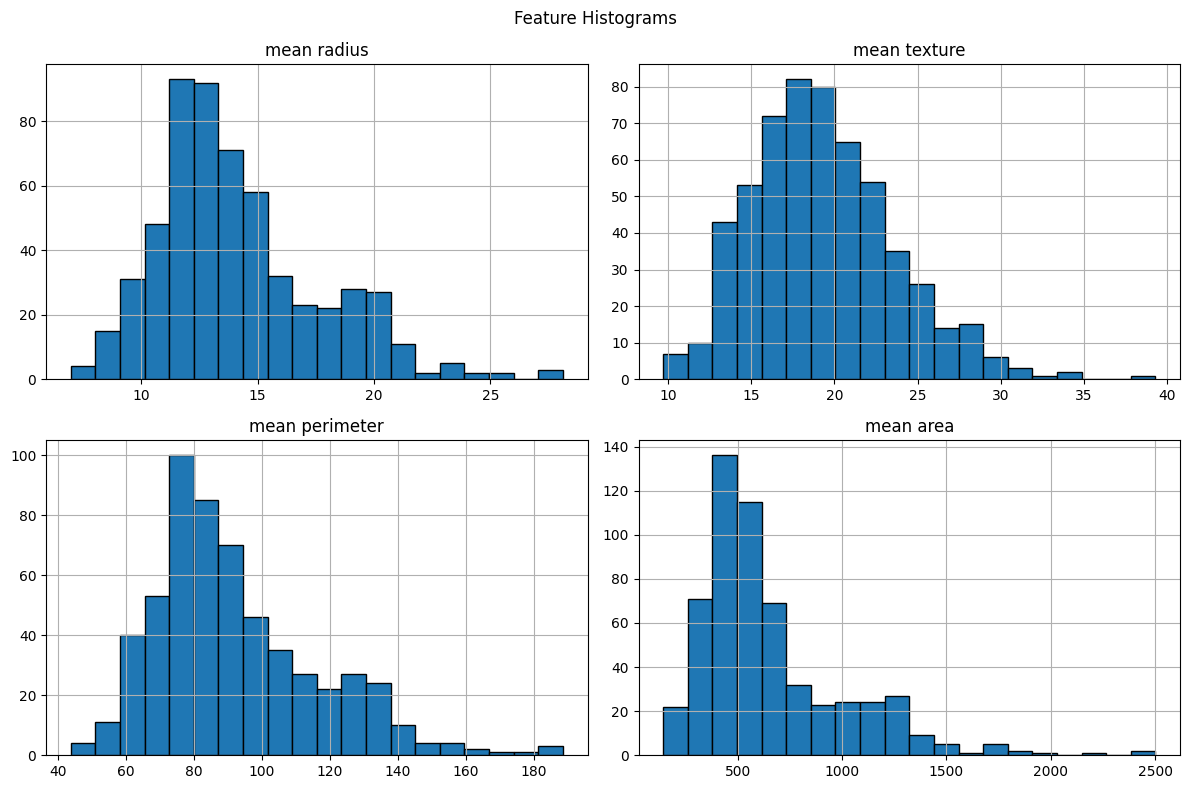

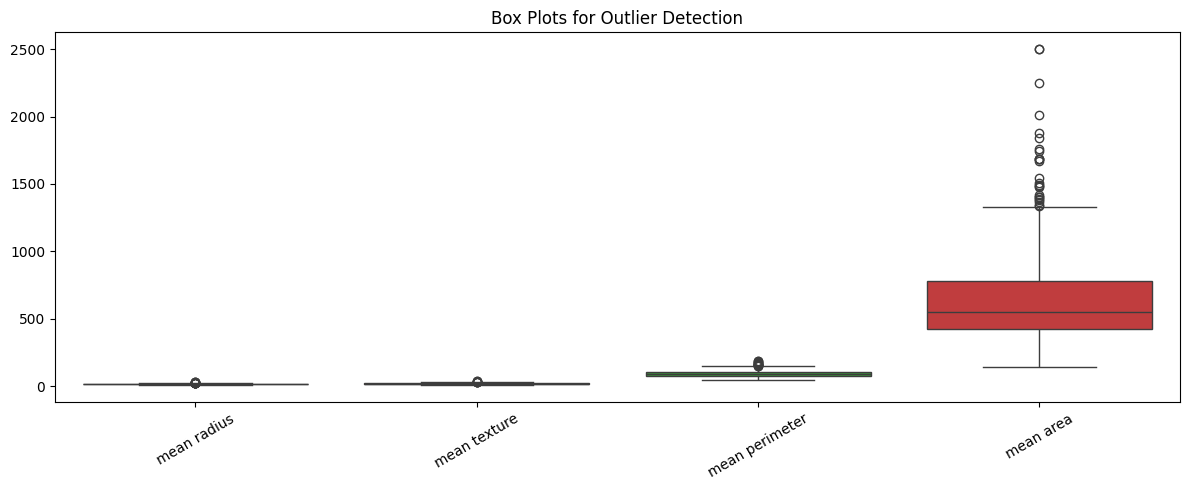

In [5]:
# Histograms of selected features
selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area"
]

X[selected_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)
plt.suptitle("Feature Histograms")
plt.tight_layout()
plt.show()

# Box plots for outlier detection
plt.figure(figsize=(12, 5))
sns.boxplot(data=X[selected_features])
plt.xticks(rotation=30)
plt.title("Box Plots for Outlier Detection")
plt.tight_layout()
plt.show()

In [6]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outlier_mask = (X < (Q1 - 1.5 * IQR)) | (
    X > (Q3 + 1.5 * IQR)
)

outlier_counts = outlier_mask.sum().sort_values(
    ascending=False
)

print("Outliers per feature:")
print(outlier_counts[outlier_counts > 0])

print("\nTotal feature-level outlier observations:",
      int(outlier_mask.sum().sum()))

print(
    "\nDecision: Retain the original measurements because "
    "extreme diagnostic measurements may carry medical information. "
    "Standardization will be applied before model training."
)

Outliers per feature:
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
worst symmetry             23
concavity error            22
texture error              20
concave points error       19
mean concavity             18
worst radius               17
worst compactness          16
mean compactness           16
mean symmetry              15
mean fractal dimension     15
worst perimeter            15
mean radius                14
mean perimeter             13
worst concavity            12
mean concave points        10
mean texture                7
worst smoothness            7
mean smoothness             6
worst texture               5
dtype: int64

Total feature-level outlier observations: 608

Decision: Retain the original measurements beca

Outcome
Benign       357
Malignant    212
Name: count, dtype: int64


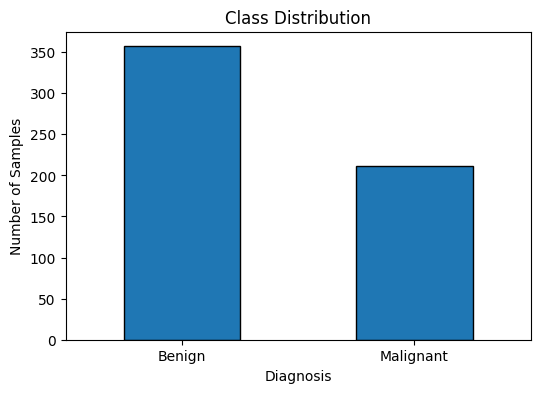


Class percentages:
Outcome
Benign       62.74
Malignant    37.26
Name: count, dtype: float64


In [7]:
class_counts = y.map({
    0: "Malignant",
    1: "Benign"
}).value_counts()

print(class_counts)

class_counts.plot(
    kind="bar",
    figsize=(6, 4),
    edgecolor="black"
)
plt.title("Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.show()

print("\nClass percentages:")
print((class_counts / len(y) * 100).round(2))

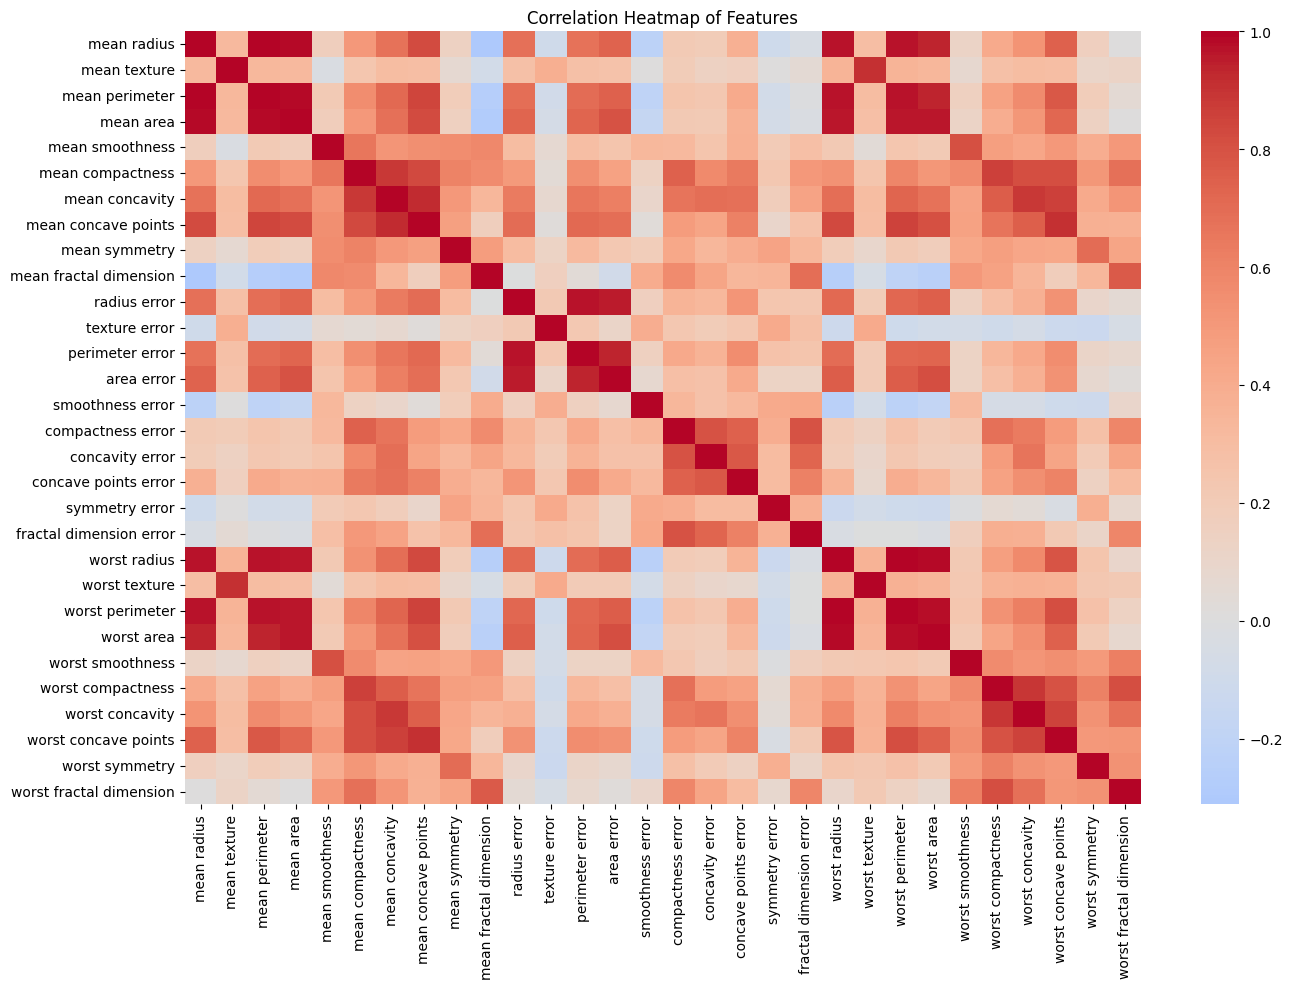

In [8]:
plt.figure(figsize=(14, 10))

correlation_matrix = X.corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    xticklabels=True,
    yticklabels=True
)

plt.title("Correlation Heatmap of Features")
plt.tight_layout()
plt.show()

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).sort_index())

Training samples: 455
Testing samples: 114

Training class proportions:
Outcome
0    0.373626
1    0.626374
Name: proportion, dtype: float64

Testing class proportions:
Outcome
0    0.368421
1    0.631579
Name: proportion, dtype: float64


In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data standardized.")
print("Testing data standardized.")

Training data standardized.
Testing data standardized.


In [11]:
model = LogisticRegression(
    max_iter=5000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [12]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("Precision (weighted):",
      round(precision_score(y_test, y_pred, average="weighted"), 4))

print("Recall (weighted):",
      round(recall_score(y_test, y_pred, average="weighted"), 4))

print("F1-score (weighted):",
      round(f1_score(y_test, y_pred, average="weighted"), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names,
    digits=4
))

Accuracy: 0.9825
Precision (weighted): 0.9825
Recall (weighted): 0.9825
F1-score (weighted): 0.9825

Classification Report:
              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



Confusion Matrix:
[[41  1]
 [ 1 71]]


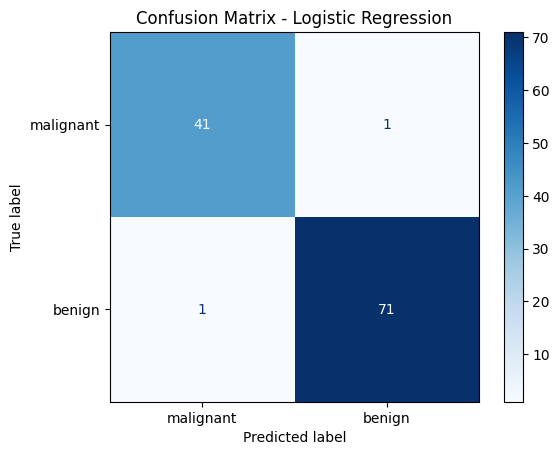

In [13]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

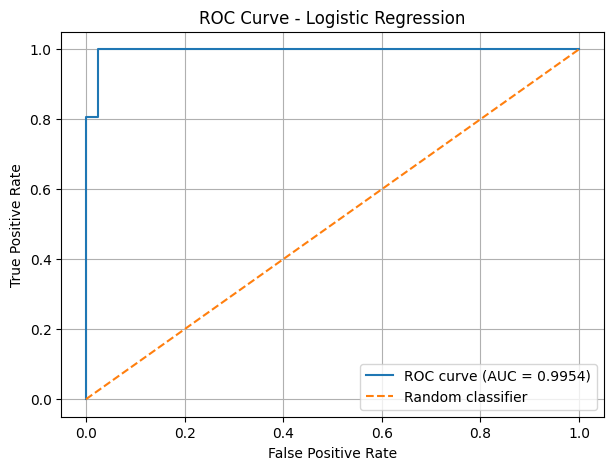

ROC-AUC Score: 0.9954


In [14]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

print("ROC-AUC Score:", round(auc_score, 4))

In [15]:
report = classification_report(
    y_test,
    y_pred,
    target_names=data.target_names,
    output_dict=True
)

print("Medical interpretation:")
print(
    "Malignant recall:",
    round(report["malignant"]["recall"], 4)
)
print(
    "Benign recall:",
    round(report["benign"]["recall"], 4)
)

malignant_recall = report["malignant"]["recall"]

print(
    "\nThe malignant recall indicates the proportion of actual "
    "malignant cases correctly identified by the model."
)
print(
    "A missed malignant case is a false negative for the "
    "malignant class, so this error deserves particular attention."
)
print(
    "\nThis model is for educational evaluation and is not "
    "a substitute for clinical diagnosis."
)

Medical interpretation:
Malignant recall: 0.9762
Benign recall: 0.9861

The malignant recall indicates the proportion of actual malignant cases correctly identified by the model.
A missed malignant case is a false negative for the malignant class, so this error deserves particular attention.

This model is for educational evaluation and is not a substitute for clinical diagnosis.
